In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_csv(
    "../data/processed/telco_churn_clean.csv"
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

Antes de analizar cualquier característica del cliente, queremos saber cómo está distribuido nuestro objetivo.

In [5]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [6]:
churn_pct = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn_pct

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

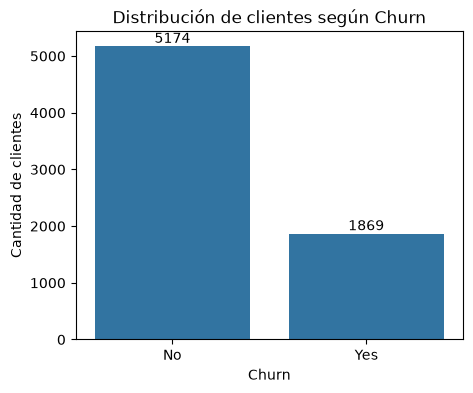

In [7]:
#Importamos las librerias de graficos
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 4))

ax = sns.countplot(data=df, x="Churn")
ax.bar_label(ax.containers[0])

plt.title("Distribución de clientes según Churn")
plt.xlabel("Churn")
plt.ylabel("Cantidad de clientes")

plt.show()

2. Churn según tipo de contrato

Esta sí es nuestra primera pregunta analítica:

¿La tasa de cancelación cambia según el tipo de contrato?

En lugar de volver a sacar conteos generales, calcularemos directamente la tasa de churn dentro de cada tipo de contrato.

In [8]:
churn_by_contract = (
    pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

churn_by_contract

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [9]:
churn_by_contract_plot = churn_by_contract.reset_index()

churn_by_contract_plot

Churn,Contract,No,Yes
0,Month-to-month,57.29,42.71
1,One year,88.73,11.27
2,Two year,97.17,2.83


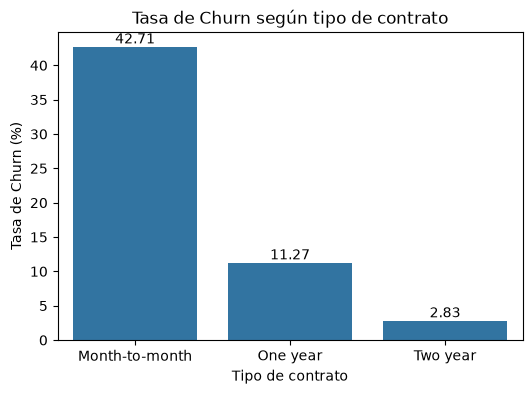

In [10]:
plt.figure(figsize=(6, 4))

ax = sns.barplot(
    data=churn_by_contract,
    x="Contract",
    y="Yes"
)
ax.bar_label(ax.containers[0])

plt.title("Tasa de Churn según tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Tasa de Churn (%)")

plt.show()

¿La antigüedad (tenure) está relacionada con el churn?

In [11]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=[
        "0-12 meses",
        "13-24 meses",
        "25-48 meses",
        "49-60 meses",
        "61-72 meses"
    ]
)

In [12]:
churn_by_tenure = (
    pd.crosstab(
        df["TenureGroup"],
        df["Churn"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

churn_by_tenure

Churn,No,Yes
TenureGroup,,
0-12 meses,52.56,47.44
13-24 meses,71.29,28.71
25-48 meses,79.61,20.39
49-60 meses,85.58,14.42
61-72 meses,93.39,6.61


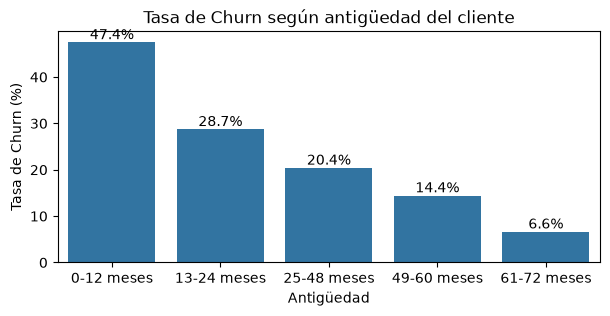

In [13]:
tenure_plot = churn_by_tenure.reset_index()

plt.figure(figsize=(7, 3))

ax = sns.barplot(
    data=tenure_plot,
    x="TenureGroup",
    y="Yes"
)

ax.bar_label(ax.containers[0], fmt="%.1f%%")

plt.title("Tasa de Churn según antigüedad del cliente")
plt.xlabel("Antigüedad")
plt.ylabel("Tasa de Churn (%)")

plt.show()

Se observa una disminución progresiva de la tasa de churn conforme aumenta la antigüedad. En este dataset, los clientes con 0–12 meses presentan 47.44% de churn, frente a 6.61% entre quienes tienen 61–72 meses.

De nuevo, lo correcto en nuestro proyecto es decir que existe una relación/asociación observada, no afirmar que la antigüedad sea por sí sola la causa.

##¿Los clientes con cargos mensuales más altos presentan una tasa de churn diferente?

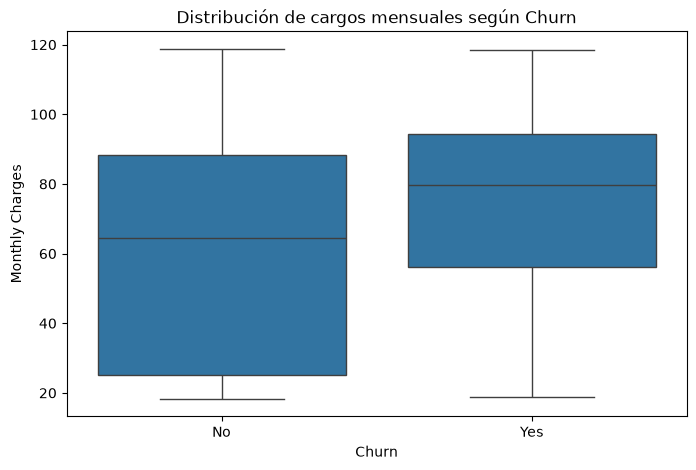

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Distribución de cargos mensuales según Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

si observamos que la caja de Yes está más arriba que la de No, podríamos decir:

Los clientes que cancelaron presentan, en este conjunto de datos, cargos mensuales generalmente más altos.

¿El tipo de servicio de Internet está relacionado con el Churn?

In [15]:
churn_by_internet = (
    pd.crosstab(
        df["InternetService"],
        df["Churn"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

churn_by_internet

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


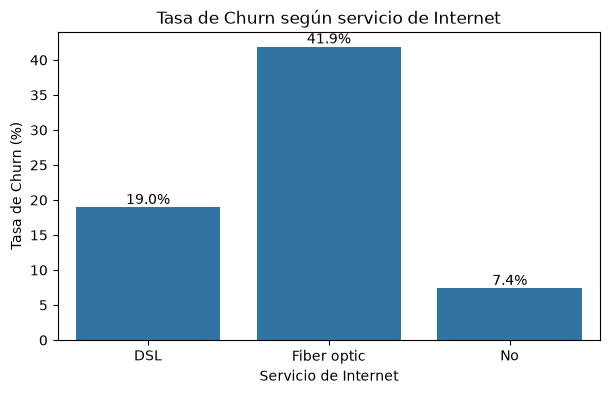

In [16]:
churn_by_internet_plot = churn_by_internet.reset_index()

plt.figure(figsize=(7, 4))

ax = sns.barplot(
    data=churn_by_internet_plot,
    x="InternetService",
    y="Yes"
)

ax.bar_label(ax.containers[0], fmt="%.1f%%")

plt.title("Tasa de Churn según servicio de Internet")
plt.xlabel("Servicio de Internet")
plt.ylabel("Tasa de Churn (%)")

plt.show()

Los clientes con servicio Fiber optic presentan una tasa de Churn considerablemente mayor que los clientes con DSL o sin servicio de Internet.

Pero ojo con algo importante para nuestro proyecto: esto muestra una asociación, no significa que tener fibra óptica sea necesariamente la causa de la cancelación. Puede estar relacionado con otras variable

¿Algunos métodos de pago están asociados con una mayor tasa de cancelación?

In [17]:
churn_by_payment = (
    pd.crosstab(
        df["PaymentMethod"],
        df["Churn"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

churn_by_payment

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


Los clientes que utilizan Electronic check presentan una tasa de cancelación considerablemente mayor que los demás grupos.

Nuevamente, hablamos de asociación, no de causalidad. No podemos concluir que el método de pago provoque la cancelación.

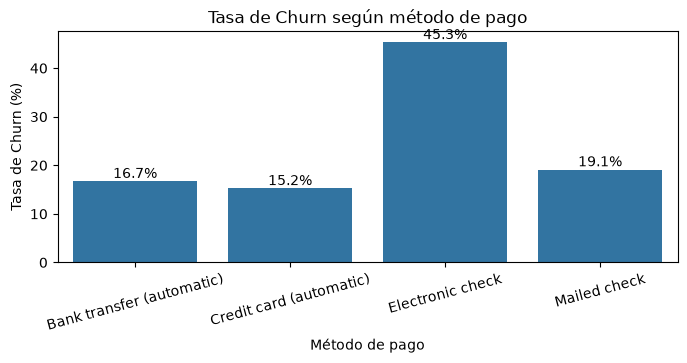

In [18]:
churn_by_payment_plot = churn_by_payment.reset_index()

plt.figure(figsize=(8, 3))

ax = sns.barplot(
    data=churn_by_payment_plot,
    x="PaymentMethod",
    y="Yes"
)

ax.bar_label(ax.containers[0], fmt="%.1f%%")

plt.title("Tasa de Churn según método de pago")
plt.xlabel("Método de pago")
plt.ylabel("Tasa de Churn (%)")

plt.xticks(rotation=15)

plt.show()

Ahora hagamos un análisis: cruzar dos variables.

Hasta ahora vimos cada variable por separado:

Contract → los contratos mensuales tienen mayor Churn.
tenure → los clientes con menor antigüedad tienen mayor Churn.

Ahora queremos saber:

¿La combinación entre tipo de contrato y antigüedad permite identificar grupos con tasas de Churn particularmente altas?

Esto es útil porque en un análisis real no siempre una variable explica todo por sí sola.

In [19]:
churn_contract_tenure = (
    pd.crosstab(
        [df["Contract"], df["TenureGroup"]],
        df["Churn"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

churn_contract_tenure

Churn                           No    Yes
Contract       TenureGroup               
Month-to-month 0-12 meses    48.65  51.35
               13-24 meses   62.28  37.72
               25-48 meses   67.08  32.92
               49-60 meses   72.22  27.78
               61-72 meses   77.78  22.22
One year       0-12 meses    89.52  10.48
               13-24 meses   91.88   8.12
               25-48 meses   89.38  10.62
               49-60 meses   86.29  13.71
               61-72 meses   87.86  12.14
Two year       0-12 meses   100.00   0.00
               13-24 meses  100.00   0.00
               25-48 meses   97.81   2.19
               49-60 meses   96.03   3.97
               61-72 meses   96.86   3.14

In [20]:
churn_heatmap = churn_contract_tenure["Yes"].unstack()

churn_heatmap

TenureGroup,0-12 meses,13-24 meses,25-48 meses,49-60 meses,61-72 meses
Contract,,,,,
Month-to-month,51.35,37.72,32.92,27.78,22.22
One year,10.48,8.12,10.62,13.71,12.14
Two year,0.00,0.00,2.19,3.97,3.14


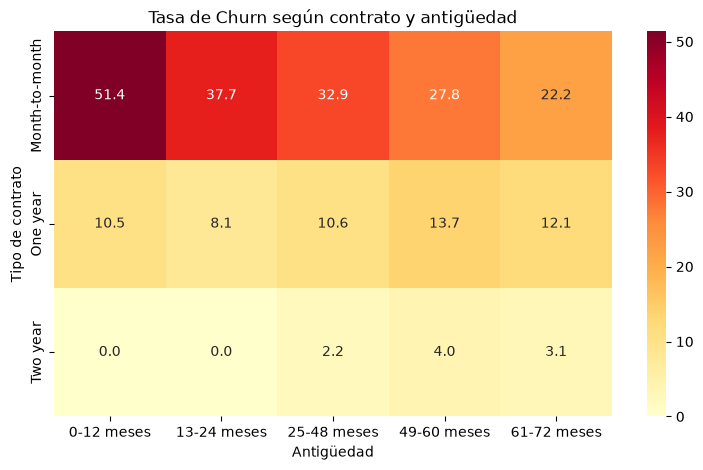

In [21]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    churn_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Tasa de Churn según contrato y antigüedad")
plt.xlabel("Antigüedad")
plt.ylabel("Tipo de contrato")

plt.show()

## Conclusiones del análisis exploratorio

A partir del análisis exploratorio se identificaron varios patrones relacionados con la variable objetivo `Churn`:

* El tipo de contrato presenta una diferencia importante en la tasa de cancelación. Los clientes con contrato `Month-to-month` presentan una tasa de Churn de **42.71%**, frente a **11.27%** en contratos de un año y **2.83%** en contratos de dos años.

* La antigüedad del cliente también muestra una relación con la cancelación. La tasa de Churn disminuye conforme aumenta el `tenure`, pasando de **47.44%** en clientes con 0–12 meses a **6.61%** en clientes con 61–72 meses.

* El servicio de Internet presenta diferencias entre grupos. Los clientes con `Fiber optic` tienen una tasa de Churn de **41.89%**, mientras que `DSL` presenta **18.96%** y los clientes sin servicio de Internet **7.40%**.

* El método de pago también muestra diferencias. Los clientes que utilizan `Electronic check` presentan una tasa de Churn de **45.29%**, superior a la observada en los demás métodos de pago.

* Al analizar conjuntamente el tipo de contrato y la antigüedad, se observa que los clientes con contrato `Month-to-month` y entre 0–12 meses de antigüedad presentan una tasa de Churn de **51.35%**.

Estos resultados muestran asociaciones relevantes entre determinadas características de los clientes y el Churn. Sin embargo, estos patrones no implican causalidad. En la siguiente etapa se prepararán las variables para construir modelos de clasificación capaces de estimar la probabilidad de cancelación.
